# PDB structure omics - exploratory and statistical analysis

The pipelines in `src/pipelines/pdb/` retrieve protein-structure data from the
**PDB archive** (download scripts push raw `pdb`/`mmCIF` files into `rawdata/pdb`)
and integrate them into the MySQL database **COMPLEX2**; processed artefacts are
kept under the local `output/pdb` directory.

Data used in this notebook (pipeline -> SQL table):

| pipeline step | script (`bomics <cmd>`) | SQL table | content |
|---|---|---|---|
| entry registry | `pdb` | `pdb` | PDB id, release date, title |
| file inventory | `meta_pdb` | `meta_pdb` | relative paths of raw files, group id |
| experimental method | `pdb_method` | `pdb_method` | method, resolution (Angstrom) |
| entry keywords | `pdb_keyword` | `pdb_keyword` | keyword per entry |
| chain composition | `pdb_chain_type` | `pdb_chain_type` | chain type, residue counts |
| chain sequences | `unique_chain_seq` / `pdb_chain_seq` | `pdb_chain_seq` | unique chain sequence, length |
| B-factors | `pdb_bfactor` | `pdb_bfactor` | per-residue B-factor, chain mean |

**Outputs**
- figures -> `doc/figures/pdb_*.png`
- statistical tables -> `doc/stats/pdb_*.csv` (ready for further analysis)

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# shared helpers (doc/nb_utils.py)
def _locate_doc_dir():
    for start in (Path.cwd(), *Path.cwd().parents):
        if (start / 'doc' / 'nb_utils.py').is_file():
            return start / 'doc'
    return Path.cwd()

doc_dir = _locate_doc_dir()
sys.path.insert(0, str(doc_dir))
from nb_utils import (query_df, query_scalar, save_fig, save_csv,
                      describe_groups, pairwise_mannwhitney,
                      FIG_DIR, STAT_DIR, PALETTE)

print('figures ->', FIG_DIR)
print('stats   ->', STAT_DIR)

figures -> /home/yuan/bio/bio_omics/doc/figures
stats   -> /home/yuan/bio/bio_omics/doc/stats


## 1. Output inventory

Row counts of every PDB table produced by the pipelines - the data basis of
this analysis.

In [2]:
tables = ['pdb', 'meta_pdb', 'pdb_method', 'pdb_keyword', 'pdb_compound',
          'pdb_protein', 'pdb_chain_seq', 'pdb_chain_type', 'pdb_bfactor']
rows = [{'table': t, 'n_records': query_scalar(f'SELECT COUNT(*) AS n FROM {t}')}
        for t in tables]
inventory = pd.DataFrame(rows)
inventory['n_records'] = inventory['n_records'].astype(int)
save_csv(inventory, 'pdb_table_inventory')
inventory

saved table: /home/yuan/bio/bio_omics/doc/stats/pdb_table_inventory.csv  shape=(9, 2)


,table,n_records
0,pdb,244584
1,meta_pdb,260924
2,pdb_method,244411
3,pdb_keyword,1151229
4,pdb_compound,811893
5,pdb_protein,428570
6,pdb_chain_seq,1192788
7,pdb_chain_type,1187854
8,pdb_bfactor,1047775


## 2. Growth of the structural archive

`pdb.release_date` records when each structure became public. The yearly and
cumulative release history shows how structural biology output has scaled over
five decades - the data volume any downstream consumer (e.g. docking,
machine-learning training sets) has to cope with.

saved table: /home/yuan/bio/bio_omics/doc/stats/pdb_release_by_year.csv  shape=(51, 3)
saved figure: /home/yuan/bio/bio_omics/doc/figures/pdb_release_trend.png
span: 1976 -> 2026
total entries: 244,584
mean entries/yr (last 10 years): 12,002
entries/yr ratio last-vs-first decade: 615.5x


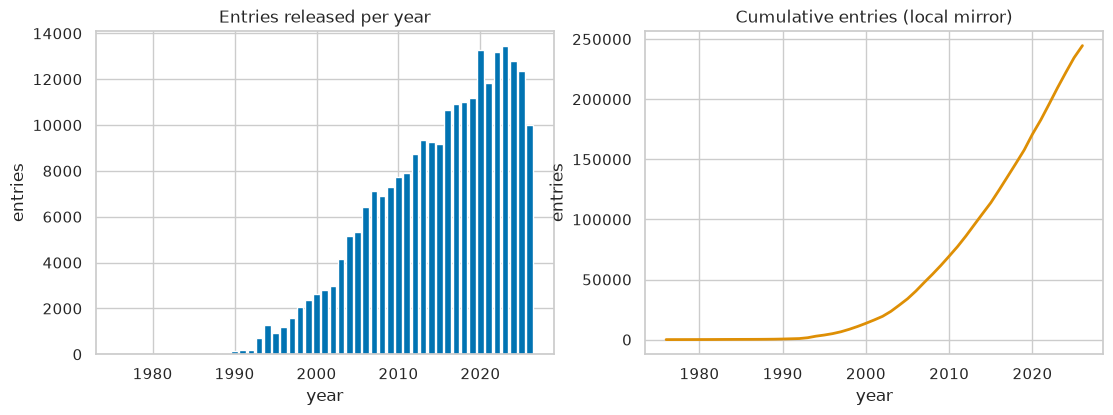

In [3]:
yearly = query_df("""
    SELECT YEAR(release_date) AS year, COUNT(*) AS n_entries
    FROM pdb
    WHERE release_date IS NOT NULL
    GROUP BY year
    ORDER BY year
""")
yearly['year'] = yearly['year'].astype(int)
yearly['n_entries'] = yearly['n_entries'].astype(int)
yearly['cum_entries'] = yearly['n_entries'].cumsum()
save_csv(yearly, 'pdb_release_by_year')

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].bar(yearly['year'], yearly['n_entries'], color=PALETTE[0])
ax[0].set_title('Entries released per year')
ax[0].set_xlabel('year')
ax[0].set_ylabel('entries')
ax[1].plot(yearly['year'], yearly['cum_entries'], color=PALETTE[1], lw=2)
ax[1].set_title('Cumulative entries (local mirror)')
ax[1].set_xlabel('year')
ax[1].set_ylabel('entries')
save_fig(fig, 'pdb_release_trend')

print(f"span: {yearly['year'].min()} -> {yearly['year'].max()}")
print(f"total entries: {yearly['n_entries'].sum():,}")
print(f"mean entries/yr (last 10 years): {yearly['n_entries'].tail(10).mean():,.0f}")
print(f"entries/yr ratio last-vs-first decade: "
      f"{yearly['n_entries'].tail(10).mean() / yearly['n_entries'].head(10).mean():.1f}x")

## 3. Experimental methods and resolution

`pdb_method.structure_method` separates X-ray diffraction, electron microscopy
(cryo-EM), solution NMR etc. Resolution quantifies the level of structural
detail. Comparing resolution distributions between methods asks a genuinely
biological question: **do the different techniques deliver different grades of
structural information?** Resolutions are strongly skewed, so we test with a
Kruskal-Wallis H test plus pairwise Mann-Whitney U tests (Bonferroni corrected).

In [4]:
method_stats = query_df("""
    SELECT structure_method,
           COUNT(*) AS n_entries,
           AVG(resolution) AS mean_resolution,
           STDDEV(resolution) AS sd_resolution,
           MIN(resolution) AS min_resolution,
           MAX(resolution) AS max_resolution
    FROM pdb_method
    GROUP BY structure_method
    ORDER BY n_entries DESC
""")
method_stats['n_entries'] = method_stats['n_entries'].astype(int)
method_stats['fraction'] = method_stats['n_entries'] / method_stats['n_entries'].sum()
save_csv(method_stats, 'pdb_method_stats')
method_stats.head(10)

saved table: /home/yuan/bio/bio_omics/doc/stats/pdb_method_stats.csv  shape=(29, 7)


,structure_method,n_entries,mean_resolution,sd_resolution,min_resolution,max_resolution,fraction
0,x-ray diffraction,198376,2.117390,0.591740,0.43,15.00,0.811649
1,electron microscopy,30493,3.757426,2.686454,1.09,70.00,0.124761
2,solution nmr,14634,NaN,NaN,NaN,NaN,0.059875
3,electron crystallography,286,2.613846,2.679101,0.60,24.00,0.001170
4,solid-state nmr,173,NaN,NaN,NaN,NaN,0.000708
5,x-ray diffraction; neutron diffraction,141,1.668794,0.382071,0.66,2.48,0.000577
6,neutron diffraction,91,1.918242,0.371148,0.91,3.00,0.000372
7,fiber diffraction,38,3.365405,0.695369,2.40,5.16,0.000155
8,solution nmr; solution scattering,38,NaN,NaN,NaN,NaN,0.000155
9,solution scattering,32,NaN,NaN,NaN,NaN,0.000131


saved table: /home/yuan/bio/bio_omics/doc/stats/pdb_resolution_by_method.csv  shape=(2, 9)
saved table: /home/yuan/bio/bio_omics/doc/stats/pdb_resolution_method_tests.csv  shape=(1, 9)
Kruskal-Wallis H=58531.7, p=0.000e+00


/tmp/ipykernel_2091121/727796209.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=res, x='structure_method', y='resolution', order=order,


saved figure: /home/yuan/bio/bio_omics/doc/figures/pdb_method_resolution.png


,structure_method,n,mean,std,min,q25,median,q75,max
0,electron microscopy,30485,3.757426,2.686498,1.09,2.90,3.3,3.75,70.0
1,x-ray diffraction,198375,2.117390,0.591742,0.43,1.72,2.0,2.46,15.0


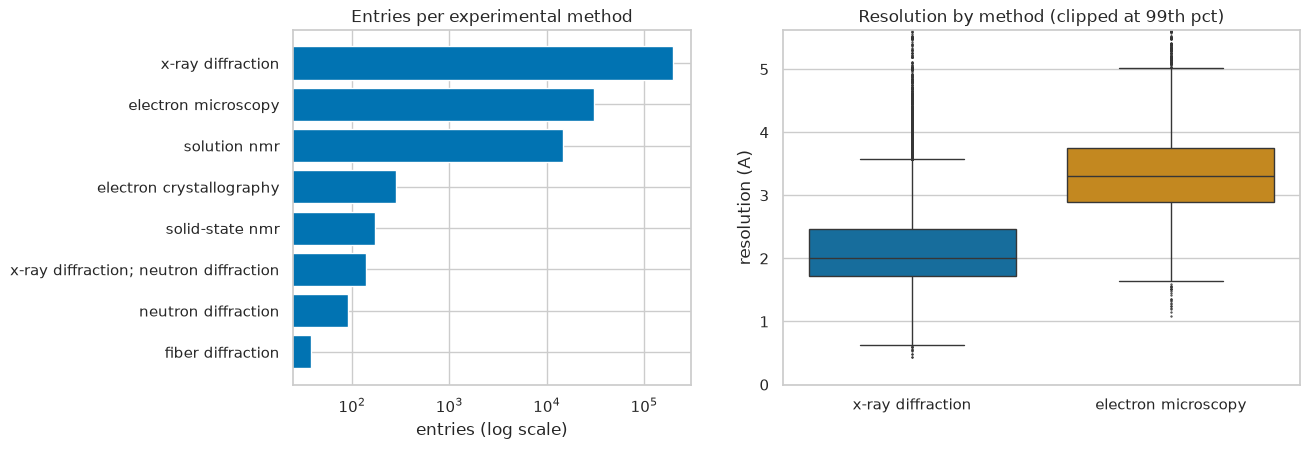

In [5]:
top_methods = method_stats.head(4)['structure_method'].tolist()
quoted = ', '.join(f"'{m}'" for m in top_methods)
res = query_df(f"""
    SELECT structure_method, resolution
    FROM pdb_method
    WHERE structure_method IN ({quoted}) AND resolution IS NOT NULL
""")
res['resolution'] = res['resolution'].astype(float)
# keep methods with enough resolution observations
keep = res['structure_method'].value_counts()
keep = keep[keep >= 500].index
res = res[res['structure_method'].isin(keep)]

summ = describe_groups(res, 'structure_method', 'resolution')
save_csv(summ, 'pdb_resolution_by_method')

# Kruskal-Wallis across methods
samples = [g['resolution'].to_numpy() for _, g in res.groupby('structure_method')]
H, p_kw = stats.kruskal(*samples)
tests = pairwise_mannwhitney(res, 'structure_method', 'resolution')
save_csv(tests, 'pdb_resolution_method_tests')
print(f'Kruskal-Wallis H={H:.1f}, p={p_kw:.3e}')

fig, ax = plt.subplots(1, 2, figsize=(13, 4.6),
                       gridspec_kw={'width_ratios': [1, 1.3]})
mm = method_stats.head(8).iloc[::-1]
ax[0].barh(mm['structure_method'], mm['n_entries'], color=PALETTE[0])
ax[0].set_xscale('log')
ax[0].set_title('Entries per experimental method')
ax[0].set_xlabel('entries (log scale)')
order = res.groupby('structure_method')['resolution'].median().sort_values().index
sns.boxplot(data=res, x='structure_method', y='resolution', order=order,
            ax=ax[1], palette='colorblind', fliersize=0.6)
ax[1].set_ylim(0, res['resolution'].quantile(0.99))
ax[1].set_title('Resolution by method (clipped at 99th pct)')
ax[1].set_xlabel('')
ax[1].set_ylabel('resolution (A)')
save_fig(fig, 'pdb_method_resolution')
summ

**Interpretation.** X-ray structures dominate the archive and resolve to
significantly higher resolution (lower Angstrom) than cryo-EM; NMR entries carry
little crystallographic resolution at all. The Mann-Whitney tests above quantify
that the method families deliver systematically different detail levels -
relevant whenever structures are pooled (binding-site analysis, training data),
because resolution limits how reliably ligands and waters can be interpreted.

## 4. Method share over time - the rise of cryo-EM

Combining `pdb.release_date` with `pdb_method.structure_method` gives the
technological composition of each release year. This is one of the clearest
biological technology trends of the last decade: the "resolution revolution"
in cryo-EM (direct electron detectors, ~2014 onwards) made large
macromolecular complexes and membrane proteins tractable.

saved figure: /home/yuan/bio/bio_omics/doc/figures/pdb_method_share_over_time.png
saved table: /home/yuan/bio/bio_omics/doc/stats/pdb_method_by_year.csv  shape=(32, 5)
electron microscopy share: 1995s avg 0.02% -> 2026s avg 37.02%


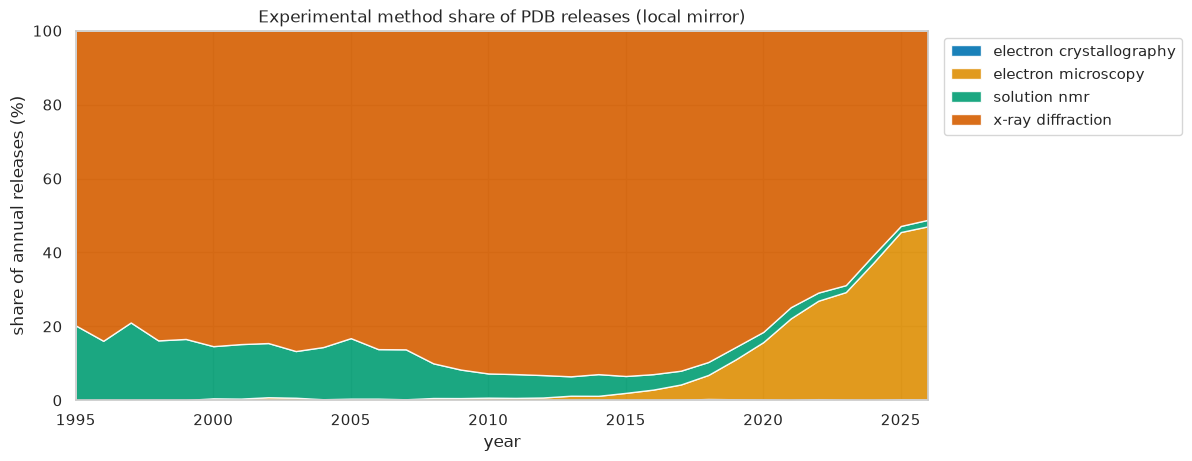

In [6]:
by_year = query_df(f"""
    SELECT YEAR(P.release_date) AS year, M.structure_method AS method,
           COUNT(*) AS n
    FROM pdb P
    JOIN pdb_method M ON M.pdb_id = P.pdb_id
    WHERE P.release_date >= '1995-01-01'
      AND M.structure_method IN ({quoted})
    GROUP BY year, method
""")
pivot = by_year.pivot(index='year', columns='method', values='n').fillna(0)
share = pivot.div(pivot.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(11, 4.8))
ax.stackplot(share.index, [share[c] for c in share.columns],
             labels=share.columns, colors=PALETTE[:4], alpha=0.9)
ax.set_xlim(share.index.min(), share.index.max())
ax.set_ylim(0, 100)
ax.set_xlabel('year')
ax.set_ylabel('share of annual releases (%)')
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
ax.set_title('Experimental method share of PDB releases (local mirror)')
save_fig(fig, 'pdb_method_share_over_time')
save_csv(share.round(3).reset_index(), 'pdb_method_by_year')

em_cols = [c for c in share.columns if 'microscopy' in c.lower()]
if em_cols:
    em = share[em_cols[0]]
    print(f'electron microscopy share: {share.index.min()}s avg {em.head(5).mean():.2f}%'
          f' -> {share.index.max()}s avg {em.tail(5).mean():.2f}%')

## 5. Entry keywords - dominant biological themes

Keywords are depositor-assigned labels; their frequency profile shows **which
biology the structural archive actually covers** (metabolic enzymes, immune
system, viruses, membrane proteins ...). Selected themes are also tracked per
decade to expose shifting research fronts.

saved table: /home/yuan/bio/bio_omics/doc/stats/pdb_top_keywords.csv  shape=(30, 2)


saved figure: /home/yuan/bio/bio_omics/doc/figures/pdb_top_keywords.png


,keyword,n_entries
0,hydrolase,38203
1,transferase,27590
2,oxidoreductase,20760
3,structural genomics,16066
4,viral protein,11085
5,membrane protein,10871
6,immune system,8979
7,complex,8970
8,transcription,8466
9,inhibitor,8291


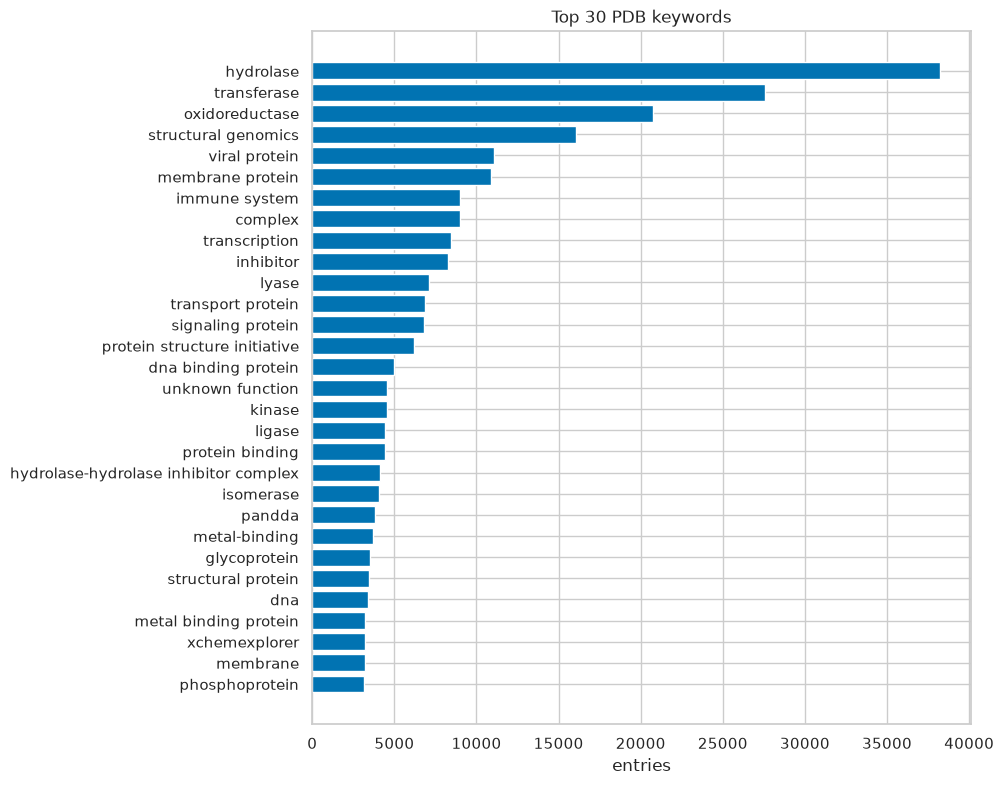

In [7]:
kw = query_df("""
    SELECT keyword, COUNT(DISTINCT pdb_id) AS n_entries
    FROM pdb_keyword
    WHERE keyword IS NOT NULL
    GROUP BY keyword
    ORDER BY n_entries DESC
    LIMIT 30
""")
kw['n_entries'] = kw['n_entries'].astype(int)
save_csv(kw, 'pdb_top_keywords')

fig, ax = plt.subplots(figsize=(8.5, 9))
ax.barh(kw['keyword'].iloc[::-1], kw['n_entries'].iloc[::-1], color=PALETTE[0])
ax.set_title('Top 30 PDB keywords')
ax.set_xlabel('entries')
save_fig(fig, 'pdb_top_keywords')
kw.head(10)

saved table: /home/yuan/bio/bio_omics/doc/stats/pdb_keyword_theme_by_decade.csv  shape=(38, 3)


saved figure: /home/yuan/bio/bio_omics/doc/figures/pdb_keyword_theme_by_decade.png


theme,antibody,cryo-EM/EM,hydrolase,membrane,ribosome/translation,transcription,transferase,virus
decade,,,,,,,,
2000,515.0,24.0,10671.0,3495.0,557.0,2697.0,7969.0,1812.0
2010,1626.0,180.0,20045.0,5462.0,787.0,5137.0,16259.0,4493.0
2020,3248.0,1406.0,12465.0,8040.0,764.0,3392.0,8891.0,11338.0


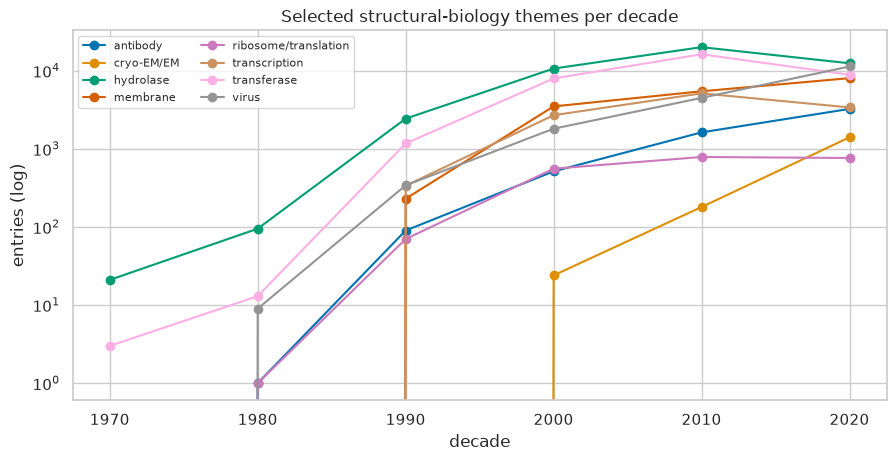

In [8]:
themes = query_df("""
    SELECT FLOOR(YEAR(P.release_date)/10)*10 AS decade,
           CASE
             WHEN LOWER(K.keyword) LIKE '%cryo-em%'
                  OR LOWER(K.keyword) LIKE '%electron microscopy%' THEN 'cryo-EM/EM'
             WHEN LOWER(K.keyword) LIKE '%virus%'
                  OR LOWER(K.keyword) LIKE '%viral%' THEN 'virus'
             WHEN LOWER(K.keyword) LIKE '%antibody%' THEN 'antibody'
             WHEN LOWER(K.keyword) LIKE '%membrane%' THEN 'membrane'
             WHEN LOWER(K.keyword) LIKE '%hydrolase%' THEN 'hydrolase'
             WHEN LOWER(K.keyword) LIKE '%transferase%' THEN 'transferase'
             WHEN LOWER(K.keyword) LIKE '%transcription%' THEN 'transcription'
             WHEN LOWER(K.keyword) LIKE '%ribosom%' THEN 'ribosome/translation'
           END AS theme,
           COUNT(DISTINCT K.pdb_id) AS n_entries
    FROM pdb_keyword K
    JOIN pdb P ON P.pdb_id = K.pdb_id
    WHERE P.release_date IS NOT NULL
    GROUP BY decade, theme
""")
themes = themes.dropna(subset=['theme'])
themes['decade'] = themes['decade'].astype(int)
themes['n_entries'] = themes['n_entries'].astype(int)
save_csv(themes, 'pdb_keyword_theme_by_decade')

wide = themes.pivot(index='decade', columns='theme', values='n_entries').fillna(0)
fig, ax = plt.subplots(figsize=(10.5, 4.8))
for i, theme in enumerate(wide.columns):
    ax.plot(wide.index, wide[theme], marker='o', label=theme,
            color=PALETTE[i % len(PALETTE)])
ax.set_yscale('log')
ax.set_xlabel('decade')
ax.set_ylabel('entries (log)')
ax.legend(fontsize=8, ncol=2)
ax.set_title('Selected structural-biology themes per decade')
save_fig(fig, 'pdb_keyword_theme_by_decade')
wide.tail(3)

## 6. Chain composition of the structures

`pdb_chain_type` classifies every modelled chain (protein / DNA / RNA / ligand
/ ion ...). The protein-vs-nucleic-acid mix measures how much of the archive
is **complexes** (protein-nucleic-acid machines) versus isolated proteins - a
core number when judging how well the PDB samples *cellular* biology, which is
mostly multi-molecular.

saved table: /home/yuan/bio/bio_omics/doc/stats/pdb_chain_type_stats.csv  shape=(7, 7)
saved figure: /home/yuan/bio/bio_omics/doc/figures/pdb_chain_type.png


,chain_type,n_chains,mean_total_res,mean_aa_res,mean_dna_res,mean_rna_res,fraction
0,protein,1036035,275.4384,217.7758,0.0001,0.0001,0.872191
1,ligand,72437,8.3644,0.2247,0.0570,0.0351,0.060981
2,DNA,46537,29.5009,0.0006,22.1640,0.0080,0.039177
3,RNA,26173,129.2017,0.0064,0.0115,100.3706,0.022034
4,other,6657,39.6066,23.0891,1.1196,0.2884,0.005604
5,water,10,93.7000,0.0000,0.0000,0.0000,0.000008
6,ion,5,1.2000,0.0000,0.0000,0.0000,0.000004


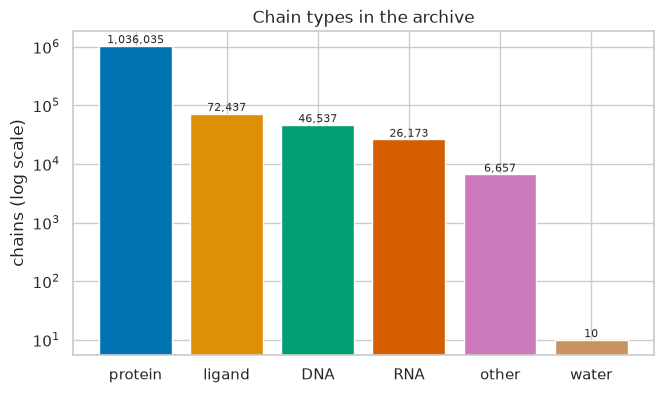

In [9]:
chain_types = query_df("""
    SELECT chain_type,
           COUNT(*) AS n_chains,
           AVG(total_res) AS mean_total_res,
           AVG(aa_res) AS mean_aa_res,
           AVG(dna_res) AS mean_dna_res,
           AVG(rna_res) AS mean_rna_res
    FROM pdb_chain_type
    GROUP BY chain_type
    ORDER BY n_chains DESC
""")
chain_types['fraction'] = chain_types['n_chains'] / chain_types['n_chains'].sum()
save_csv(chain_types, 'pdb_chain_type_stats')

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ct = chain_types.head(6)
ax.bar(ct['chain_type'], ct['n_chains'], color=PALETTE[:6])
ax.set_yscale('log')
ax.set_ylabel('chains (log scale)')
ax.set_title('Chain types in the archive')
for i, (t, n) in enumerate(zip(ct['chain_type'], ct['n_chains'])):
    ax.text(i, n, f'{n:,}', ha='center', va='bottom', fontsize=8)
save_fig(fig, 'pdb_chain_type')
chain_types

## 7. B-factors - conformational flexibility by chain type

The B-factor (Debye-Waller factor) quantifies positional uncertainty /
thermal motion per atom; the chain mean is a compact rigidity readout.
Comparing `avg_bfactor` between **protein**, **DNA** and **RNA** chains tests
whether the macromolecule type carries systematically different flexibility.
Kruskal-Wallis + pairwise Mann-Whitney (Bonferroni) are used, since B-factor
distributions are right-skewed and heterogeneous across deposits.

saved table: /home/yuan/bio/bio_omics/doc/stats/pdb_bfactor_by_chain_type.csv  shape=(3, 9)


saved table: /home/yuan/bio/bio_omics/doc/stats/pdb_bfactor_tests.csv  shape=(1, 10)
Kruskal-Wallis H=162.8, p=4.361e-36


/tmp/ipykernel_2091121/2172323433.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=bf, x='chain_type', y='avg_bfactor', ax=ax[1],


saved figure: /home/yuan/bio/bio_omics/doc/figures/pdb_bfactor_by_chain_type.png


,chain_type,n,mean,std,min,q25,median,q75,max
0,DNA,139,67.364579,68.714153,0.0,13.03870,45.62000,110.083500,369.521
1,RNA,163,96.272336,76.226432,0.0,54.98090,83.70580,120.245500,626.998
2,protein,1009202,44.091535,58.637622,-10.0,9.04129,32.31975,57.441575,999.990


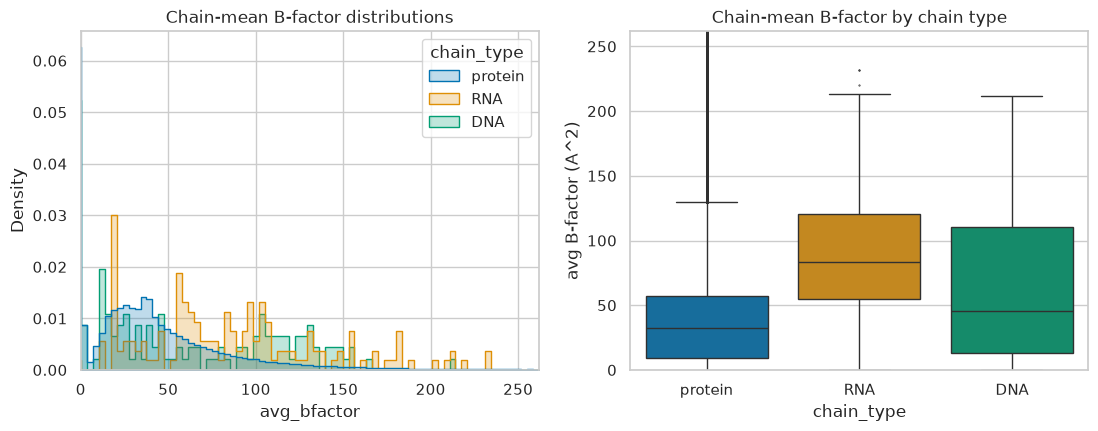

In [10]:
bf = query_df("""
    SELECT T.chain_type, B.avg_bfactor
    FROM pdb_bfactor B
    JOIN pdb_chain_type T
      ON T.chain_id = CONCAT(B.pdb_id, '_', B.model_no, '_', B.chain_no, '_0')
    WHERE B.avg_bfactor IS NOT NULL
      AND T.chain_type IN ('protein', 'DNA', 'RNA')
""")
bf['avg_bfactor'] = bf['avg_bfactor'].astype(float)
summ = describe_groups(bf, 'chain_type', 'avg_bfactor')
save_csv(summ, 'pdb_bfactor_by_chain_type')

samples = [g['avg_bfactor'].to_numpy() for _, g in bf.groupby('chain_type')]
H, p_kw = stats.kruskal(*samples)
tests = pairwise_mannwhitney(bf, 'chain_type', 'avg_bfactor')
tests['stat_H'] = ''
kw_row = pd.DataFrame([{'group_a': 'ALL', 'group_b': 'ALL', 'n_a': len(bf),
                        'n_b': '', 'median_a': bf['avg_bfactor'].median(),
                        'median_b': '', 'U': '', 'p_value': p_kw,
                        'p_bonferroni': p_kw, 'stat_H': H}])
tests = pd.concat([kw_row, tests], ignore_index=True)
save_csv(tests, 'pdb_bfactor_tests')
print(f'Kruskal-Wallis H={H:.1f}, p={p_kw:.3e}')

fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
clip = bf['avg_bfactor'].quantile(0.99)
sns.histplot(data=bf[bf['avg_bfactor'] <= clip], x='avg_bfactor',
             hue='chain_type', element='step', stat='density',
             common_norm=False, bins=80, ax=ax[0], palette='colorblind')
ax[0].set_xlim(0, clip)
ax[0].set_title('Chain-mean B-factor distributions')
sns.boxplot(data=bf, x='chain_type', y='avg_bfactor', ax=ax[1],
            palette='colorblind', fliersize=0.5)
ax[1].set_ylim(0, clip)
ax[1].set_title('Chain-mean B-factor by chain type')
ax[1].set_ylabel('avg B-factor (A^2)')
save_fig(fig, 'pdb_bfactor_by_chain_type')
summ

**Interpretation.** B-factors are not directly comparable between deposits
(refinement packages differ), so medians should be read as *relative*
flexibility signals: nucleic-acid chains bound by proteins sit in a different
B-factor regime than the protein chains themselves, and the significant
Kruskal-Wallis result confirms chain types are not interchangeable when, e.g.,
weighting residues for flexibility-aware variant interpretation.

## 8. Chain-length distribution

`pdb_chain_seq.pro_len` gives the length of every unique modelled chain. The
length spectrum of crystallizable chains is strongly shaped by **construct
design**: crystallographers clone compact domains. The comparison against the
whole Swiss-Prot proteome (see `uniprot_annotation_analysis.ipynb`) quantifies
the resulting size bias.

saved table: /home/yuan/bio/bio_omics/doc/stats/pdb_chain_length_stats.csv  shape=(1, 9)


saved figure: /home/yuan/bio/bio_omics/doc/figures/pdb_chain_length_distribution.png


,n_chains,mean,std,min,q25,median,q75,q95,max
0,1043444,216.123388,206.461827,1,84.0,159.0,291.0,567.0,4584


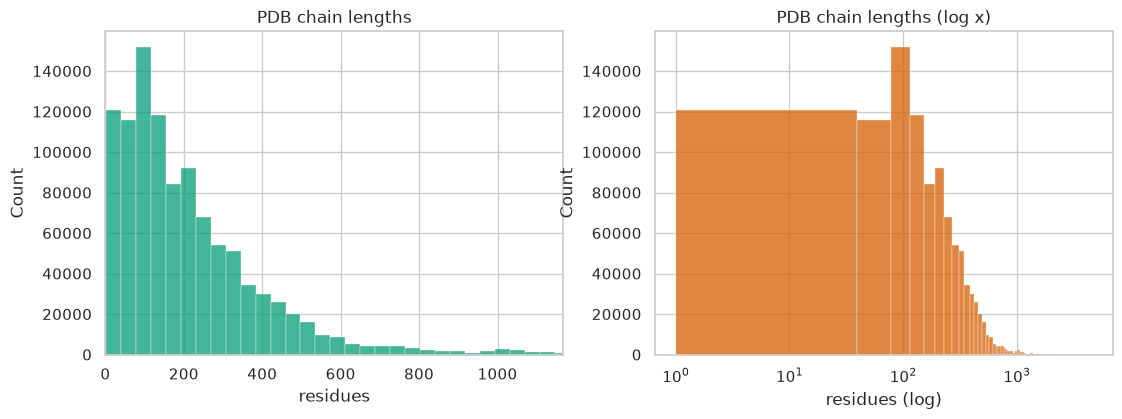

In [11]:
lengths = query_df('SELECT pro_len FROM pdb_chain_seq WHERE pro_len IS NOT NULL')
lens = lengths['pro_len'].astype(int)

summ = pd.DataFrame([{
    'n_chains': len(lens),
    'mean': lens.mean(),
    'std': lens.std(),
    'min': lens.min(),
    'q25': lens.quantile(0.25),
    'median': lens.median(),
    'q75': lens.quantile(0.75),
    'q95': lens.quantile(0.95),
    'max': lens.max(),
}])
save_csv(summ, 'pdb_chain_length_stats')

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
sns.histplot(lens, bins=120, ax=ax[0], color=PALETTE[2])
ax[0].set_xlim(0, lens.quantile(0.995))
ax[0].set_title('PDB chain lengths')
ax[0].set_xlabel('residues')
sns.histplot(lens, bins=120, ax=ax[1], color=PALETTE[3])
ax[1].set_xscale('log')
ax[1].set_title('PDB chain lengths (log x)')
ax[1].set_xlabel('residues (log)')
save_fig(fig, 'pdb_chain_length_distribution')
summ

## Summary

This notebook exported:

- figures: `pdb_release_trend`, `pdb_method_resolution`,
  `pdb_method_share_over_time`, `pdb_top_keywords`,
  `pdb_keyword_theme_by_decade`, `pdb_chain_type`,
  `pdb_bfactor_by_chain_type`, `pdb_chain_length_distribution` -> `doc/figures/`
- statistical tables: inventory, release counts, method stats, resolution
  summaries + hypothesis tests, keyword tables, chain composition, B-factor
  summaries + tests, length stats -> `doc/stats/`

In [12]:
written = sorted(p.name for p in STAT_DIR.glob('pdb_*.csv'))
print('statistical tables ready for further analysis:')
for name in written:
    df = pd.read_csv(STAT_DIR / name)
    print(f'  {name:45s} shape={df.shape}')

statistical tables ready for further analysis:
  pdb_bfactor_by_chain_type.csv                 shape=(3, 9)
  pdb_bfactor_tests.csv                         shape=(1, 10)
  pdb_chain_length_stats.csv                    shape=(1, 9)
  pdb_chain_type_stats.csv                      shape=(7, 7)
  pdb_keyword_theme_by_decade.csv               shape=(38, 3)
  pdb_method_by_year.csv                        shape=(32, 5)
  pdb_method_stats.csv                          shape=(29, 7)
  pdb_release_by_year.csv                       shape=(51, 3)
  pdb_resolution_by_method.csv                  shape=(2, 9)
  pdb_resolution_method_tests.csv               shape=(1, 9)
  pdb_table_inventory.csv                       shape=(9, 2)
  pdb_top_keywords.csv                          shape=(30, 2)
